# Planar soft arm (PCC) steered by a force at its tip

Same pipeline as the PRR notebook, for a soft continuum arm made of 3 piecewise constant curvature
segments (`src/plant/soft_PCC.py`). Joint coordinates $q_i$ are the bending angles of the segments;
the collocated coordinates are $\theta = (x_{ee},\ y_{ee},\ q_3)$ (`src/mapping/soft_PCC_theta.py`).
The same Cartesian PD (`CartesianController`) closes the loop in both cases.

The arm is elastic, so a plain PD settles with a small offset from the target: at equilibrium
$K_p\,e$ balances the elastic load. The straight arm is a singular configuration of the collocated
coordinates, so the runs go from one C-shape to another.

In [1]:
import sys
sys.path.append("../")

import numpy as np
import matplotlib.pyplot as plt

from pydrake.geometry import StartMeshcat

from src.mapping.soft_PCC_theta import PlanarSoftPCC_Theta
from src.simulation.soft_PCC_sim import simulate, summary, Q0, TARGET, KP, KD

In [2]:
def plot_log(logs, plant, title):

    times = logs["q"].sample_times()
    q, dq = logs["q"].data()[:plant.n], logs["q"].data()[plant.n:]
    x_ee, y_ee, dx_ee, dy_ee = logs["EE"].data()
    fx, fy = logs["F"].data()
    cond = [np.linalg.cond(PlanarSoftPCC_Theta.jac_h(plant, q[:, k])) for k in range(q.shape[1])]

    fig, axis = plt.subplots(3, 2, figsize=(10, 7))
    fig.suptitle(title)
    for i in range(plant.n):
        axis[0, 0].plot(times, q[i], label=f'q{i+1}')
        axis[0, 1].plot(times, dq[i], label=f'q{i+1}_dot')
    axis[0, 0].set_title('bending angles')
    axis[0, 1].set_title('bending velocities')

    axis[1, 0].plot(times, x_ee, label='x_ee')
    axis[1, 0].plot(times, y_ee, label='y_ee')
    axis[1, 0].axhline(TARGET[0], ls='--', c='C0', lw=0.8)
    axis[1, 0].axhline(TARGET[1], ls='--', c='C1', lw=0.8)
    axis[1, 0].set_title('EE position (dashed: target)')
    axis[1, 1].plot(times, dx_ee, label='x_ee_dot')
    axis[1, 1].plot(times, dy_ee, label='y_ee_dot')
    axis[1, 1].set_title('EE velocity')

    axis[2, 0].plot(times, fx, label='fx')
    axis[2, 0].plot(times, fy, label='fy')
    axis[2, 0].set_title('controller output')
    axis[2, 1].plot(times, cond, label='cond(Jac_h)')
    axis[2, 1].set_title('conditioning of the collocated coordinates')

    for ax in axis.ravel():
        ax.grid()
        ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

## Dynamics in joint coordinates q

{'tip_error': np.float64(0.027554043973903573), 'q_end': array([0.78517676, 0.92238242, 0.38419726]), 'cond_jac_h': (np.float64(7.0737256626484895), np.float64(8.87210416282042))}


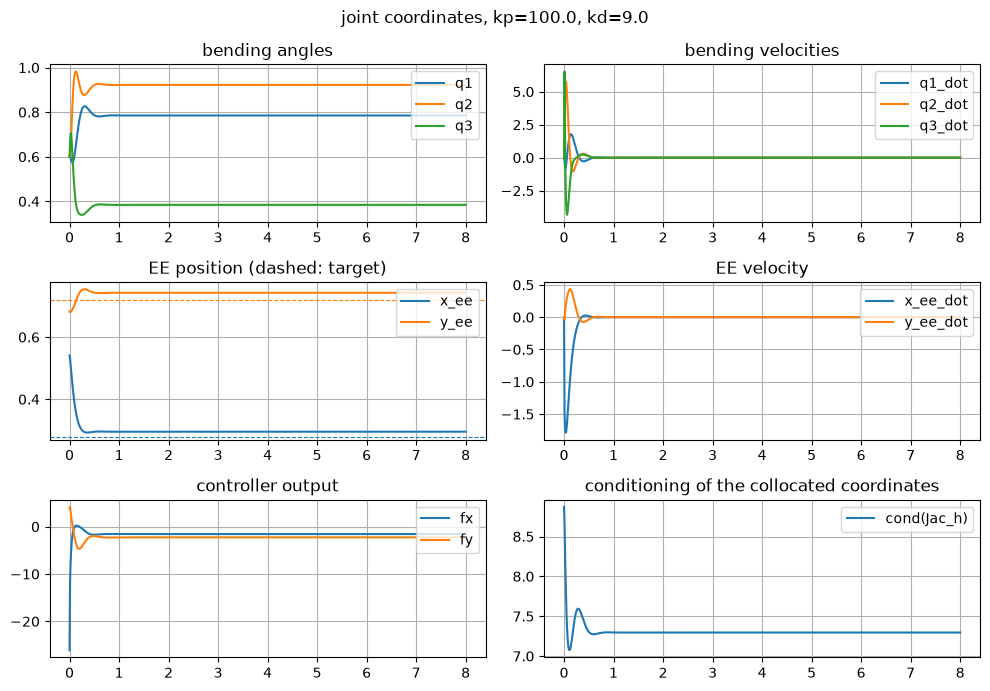

In [3]:
sim_time = 8.0
logs_q, plant_q = simulate(collocated=False, sim_time=sim_time)
print(summary(logs_q, plant_q))
plot_log(logs_q, plant_q, f'joint coordinates, kp={KP}, kd={KD}')

## Dynamics in collocated coordinates θ

{'tip_error': np.float64(0.027554043973908534), 'q_end': array([0.78517676, 0.92238242, 0.38419726]), 'cond_jac_h': (np.float64(7.0737256684721785), np.float64(8.87210416282042))}


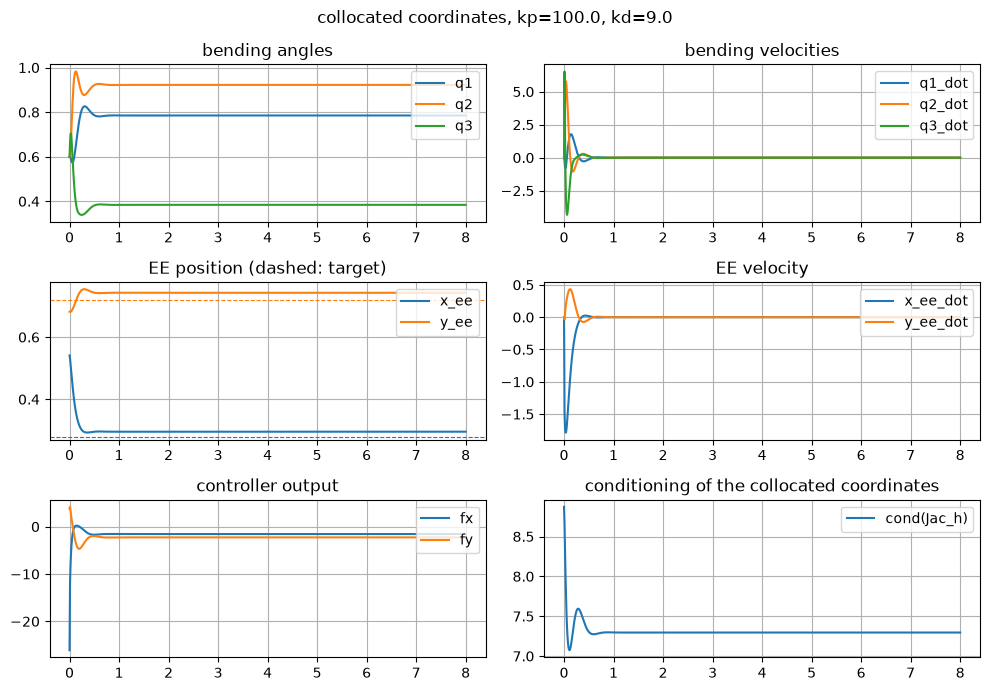

In [4]:
logs_theta, plant_theta = simulate(collocated=True, sim_time=sim_time)
print(summary(logs_theta, plant_theta))
plot_log(logs_theta, plant_theta, f'collocated coordinates, kp={KP}, kd={KD}')

A change of coordinates does not change the physics: the two runs must give the same motion.

In [5]:
q_joint, q_collocated = logs_q["q"].data(), logs_theta["q"].data()
n = min(q_joint.shape[1], q_collocated.shape[1])
print(f"max |q_joint - q_collocated| = {np.abs(q_joint[:, :n] - q_collocated[:, :n]).max():.2e}")

max |q_joint - q_collocated| = 8.21e-06


## Meshcat

The run is recorded: open *Open Controls > Animations* to replay it.

In [6]:
meshcat = StartMeshcat()

INFO:drake:Meshcat listening for connections at http://localhost:7000


In [7]:
logs_vis, _ = simulate(collocated=True, sim_time=sim_time, meshcat=meshcat)